# Practical Task

In [1]:
# Importing libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, ConfusionMatrixDisplay)

In [2]:
# Loading the dataset
df = pd.read_csv("Telco-Customer-Churn.csv")

### Data Inspection Phase

In [3]:
# Displaying the first ten rows of the dataset
df.head(10)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [4]:
# The names of the dataset's columns
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [5]:
# The data types of each column
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

### Data preprocessing phase

In [6]:
# Converting the total charges colum to numeric data type(float)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [7]:
# Checking if Total Charges data type has changed
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

In [8]:
# Checking the missing values per column
missing_values_count = df.isnull().sum()

# Look at the number of missing values in all columns
missing_values_count[0:21]

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [9]:
# Considering that Total Charges had blank rows,as the astype
# syntax didn't work to convert to colums
# Its very convenient that its only Total Charges that has missing values

# Checking all the blanks in all the colums and whitespace strings
for col in df.columns:
    if df[col].dtype == 'int64' or 'str':
        blank_count = df[col].astype(str).str.strip().eq('').sum()
        if blank_count > 0:
            print(f"{col}: {blank_count} blank value(s)")
        else:
            print(f"{col}: 0 blank values")
    else:
        print('Data type for the column is not string or interger')

customerID: 0 blank values
gender: 0 blank values
SeniorCitizen: 0 blank values
Partner: 0 blank values
Dependents: 0 blank values
tenure: 0 blank values
PhoneService: 0 blank values
MultipleLines: 0 blank values
InternetService: 0 blank values
OnlineSecurity: 0 blank values
OnlineBackup: 0 blank values
DeviceProtection: 0 blank values
TechSupport: 0 blank values
StreamingTV: 0 blank values
StreamingMovies: 0 blank values
Contract: 0 blank values
PaperlessBilling: 0 blank values
PaymentMethod: 0 blank values
MonthlyCharges: 0 blank values
TotalCharges: 0 blank values
Churn: 0 blank values


In [11]:
# Removing rows with missing values (NaN)
df.dropna(inplace=True)

In [12]:
# Once again Checking the missing values per column
missing_values_count = df.isnull().sum()

# Looking at the number of missing values in all columns
missing_values_count[0:21]

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [13]:
# Removing customerID column from the dataset
df.drop(['customerID'],inplace=True, axis=1)

In [14]:
# Reviewing the names of the dataset's columns
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [15]:
# Checking if Yes'es and No's on Churn column are capitalised
df['Churn'].unique

<bound method Series.unique of 0        No
1        No
2       Yes
3        No
4       Yes
       ... 
7038     No
7039     No
7040     No
7041    Yes
7042     No
Name: Churn, Length: 7032, dtype: str>

In [16]:
# Changign the churn column into 1: Yes and 2: No
# Cater for capitalisation as well
df['Churn'] = df['Churn'].str.strip().str.capitalize().map({'Yes': 1, 'No': 0})

In [17]:
# Reviewing the 5 rows of the data
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [18]:
# Converting all the categotical variables in the dataset into dummy variables
# Then storing them to the dataframe telecom_cust_dummies
cols = ['gender','Partner','Dependents','PhoneService','MultipleLines','InternetService','OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies','Contract','PaperlessBilling','PaymentMethod']
telecom_cust_dummies = pd.get_dummies(df, columns=cols, dtype=int)

telecom_cust_dummies.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,1,...,0,1,0,0,0,1,0,0,1,0
1,0,34,56.95,1889.50,0,0,1,1,0,1,...,0,0,1,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,1,1,0,1,...,0,1,0,0,0,1,0,0,0,1
3,0,45,42.30,1840.75,0,0,1,1,0,1,...,0,0,1,0,1,0,1,0,0,0
4,0,2,70.70,151.65,1,1,0,1,0,1,...,0,1,0,0,0,1,0,0,1,0


### Data visualisation phase

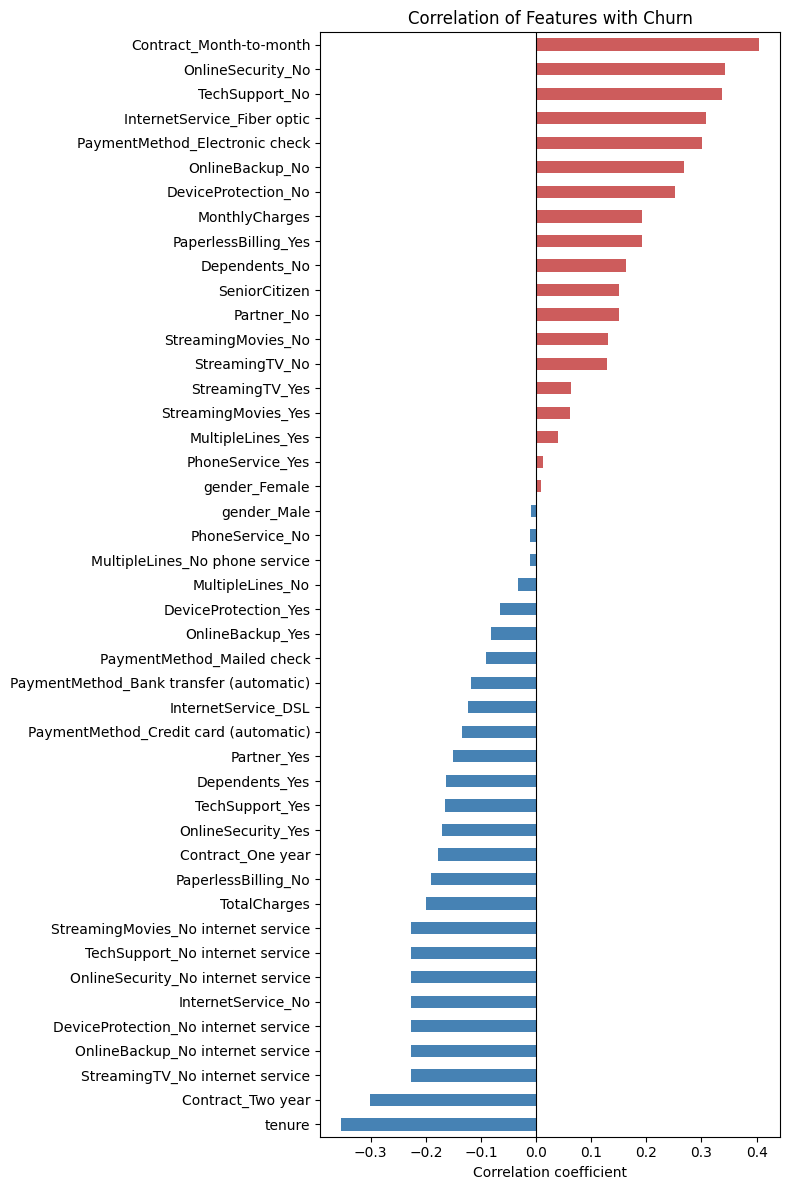

In [19]:
# Correlation of every feature with the target variable Churn
corr = telecom_cust_dummies.corr()
churn_corr = corr['Churn'].drop('Churn').sort_values()

plt.figure(figsize=(8, 12))
churn_corr.plot(kind='barh', color=(churn_corr > 0).map({True: 'indianred', False: 'steelblue'}))
plt.title('Correlation of Features with Churn')
plt.xlabel('Correlation coefficient')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

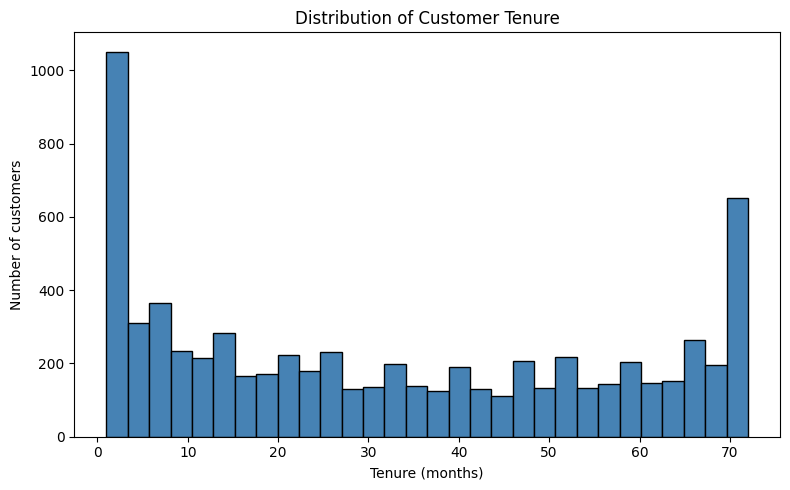

In [20]:
# Histogram of the tenure column
plt.figure(figsize=(8, 5))
plt.hist(df['tenure'], bins=30, color='steelblue', edgecolor='black')
plt.title('Distribution of Customer Tenure')
plt.xlabel('Tenure (months)')
plt.ylabel('Number of customers')
plt.tight_layout()
plt.show()

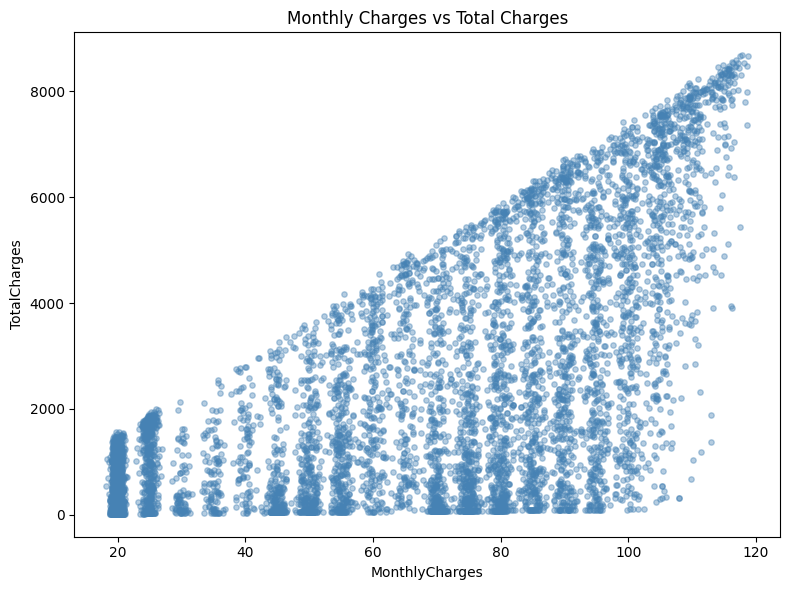

In [21]:
# Scatter plot of MonthlyCharges vs TotalCharges
plt.figure(figsize=(8, 6))
plt.scatter(df['MonthlyCharges'], df['TotalCharges'], alpha=0.4, s=15, color='steelblue')
plt.title('Monthly Charges vs Total Charges')
plt.xlabel('MonthlyCharges')
plt.ylabel('TotalCharges')
plt.tight_layout()
plt.show()

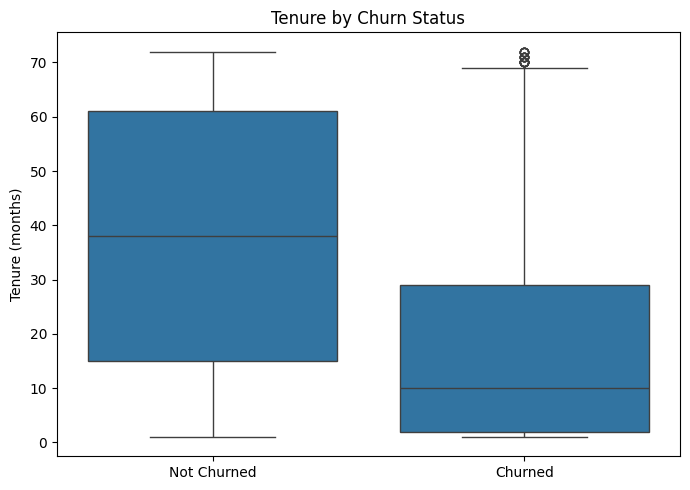

In [22]:
# Box plot: tenure for churned vs non-churned customers
plt.figure(figsize=(7, 5))
sns.boxplot(x='Churn', y='tenure', data=df)
plt.xticks([0, 1], ['Not Churned', 'Churned'])
plt.title('Tenure by Churn Status')
plt.xlabel('')
plt.ylabel('Tenure (months)')
plt.tight_layout()
plt.show()

### Preparations for ML training

In [23]:
# Scaling all variables to a range of 0 to 1 using min-max scaling
# (features only, the target Churn is left as 0/1 since it's a label, not a feature)

X = telecom_cust_dummies.drop('Churn', axis=1)
y = telecom_cust_dummies['Churn']

scaler = MinMaxScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns, index=X.index)
X_scaled.head()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0.0,0.000000,0.115423,0.001275,1.0,0.0,0.0,1.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,0.0,0.464789,0.385075,0.215867,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,0.0,0.014085,0.354229,0.010310,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,0.0,0.619718,0.239303,0.210241,0.0,1.0,1.0,0.0,1.0,0.0,...,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,0.0,0.014085,0.521891,0.015330,1.0,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


In [24]:
# Splitting the dataset into training and test sets (75% train / 25% test)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.25, random_state=42)

print(f'X_train shape: {X_train.shape}')
print(f'X_test shape:  {X_test.shape}')
print(f'y_train shape: {y_train.shape}')
print(f'y_test shape:  {y_test.shape}')

X_train shape: (5274, 45)
X_test shape:  (1758, 45)
y_train shape: (5274,)
y_test shape:  (1758,)


### Logistic regression model

In [25]:
# Importing and training a logistic regression model
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [26]:
# Making predictions on the test data
y_pred_log = log_reg.predict(X_test)

In [27]:
# Accuracy score of the logistic regression model
log_reg_accuracy = accuracy_score(y_test, y_pred_log)
print(f'Logistic Regression accuracy: {log_reg_accuracy:.4f}')

Logistic Regression accuracy: 0.7912


### Random forest model

In [28]:
# Random forest classifier with tuned hyperparameters
rf_model = RandomForestClassifier(
    n_estimators=2000,
    oob_score=True,
    max_features='sqrt',
    max_leaf_nodes=50,
    bootstrap=True,
    random_state=42
)

In [29]:
# Fitting the model
rf_model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",2000
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",50
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric(

In [30]:
# Making predictions on the test data
y_pred_rf = rf_model.predict(X_test)

In [31]:
# Accuracy score of the random forest classifier
rf_accuracy = accuracy_score(y_test, y_pred_rf)
print(f'Random Forest accuracy: {rf_accuracy:.4f}')

Random Forest accuracy: 0.7867


In [32]:
# OOB error estimation
oob_error = 1 - rf_model.oob_score_
print(f'OOB score:  {rf_model.oob_score_:.4f}')
print(f'OOB error:  {oob_error:.4f}')

OOB score:  0.8072
OOB error:  0.1928


The OOB score is 0.8072 (OOB error 0.1928), while the test accuracy above is 0.7867 -- the two are close (within about 2 percentage points), which suggests the model is generalising reasonably well rather than overfitting to the training data.

### Enhanced model evalulation

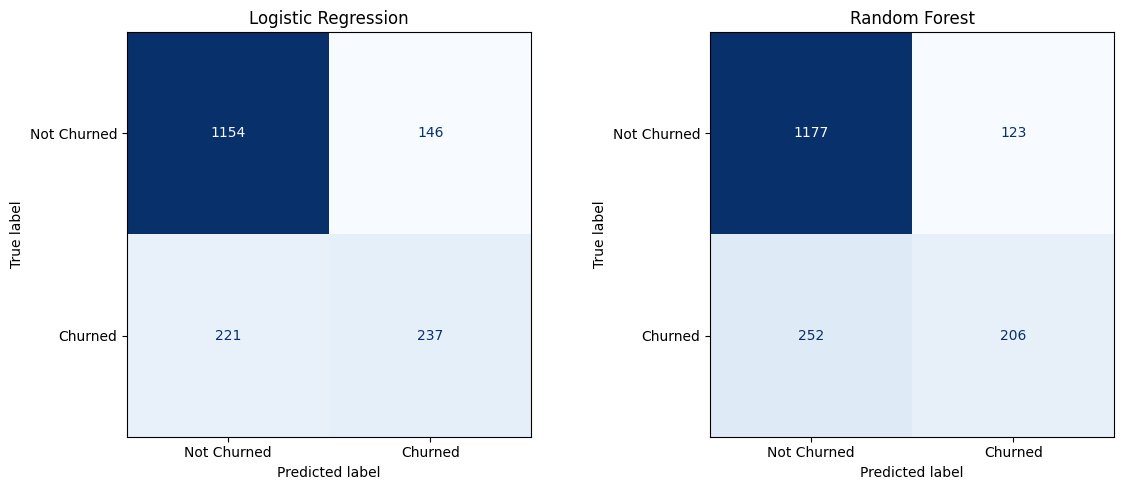

In [34]:
# Confusion matrices for both models
cm_log = confusion_matrix(y_test, y_pred_log)
cm_rf = confusion_matrix(y_test, y_pred_rf)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay(cm_log, display_labels=['Not Churned', 'Churned']).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Logistic Regression')

ConfusionMatrixDisplay(cm_rf, display_labels=['Not Churned', 'Churned']).plot(ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title('Random Forest')

plt.tight_layout()
plt.show()

In [35]:
# Precision and recall scores for each model
log_precision = precision_score(y_test, y_pred_log)
log_recall = recall_score(y_test, y_pred_log)

rf_precision = precision_score(y_test, y_pred_rf)
rf_recall = recall_score(y_test, y_pred_rf)

print('Logistic Regression -> Precision: {:.4f}, Recall: {:.4f}'.format(log_precision, log_recall))
print('Random Forest       -> Precision: {:.4f}, Recall: {:.4f}'.format(rf_precision, rf_recall))

Logistic Regression -> Precision: 0.6188, Recall: 0.5175
Random Forest       -> Precision: 0.6261, Recall: 0.4498


For both models, the top-left cell (true negatives) is by far the largest, most non-churning customers are correctly identified. The bottom-right cell (true positives, churners correctly caught) is much smaller, and the bottom-left cell (false negatives, churners the model missed) is a meaningful chunk of all actual churners. This pattern is typical of an imbalanced target; there are simply more "No" customers than "Yes" customers in this dataset, so both models find it easier to be right about the majority class.

Precision tells us: of the customers the model *flagged* as churners, how many actually churned. Recall tells us: of the customers who *actually* churned, how many the model caught. Logistic regression scores 0.6188 precision / 0.5175 recall, and random forest scores 0.6261 precision / 0.4498 recall, so random forest is slightly more precise, but logistic regression catches noticeably more of the actual churners (recall). Both recall scores sit well below 50-60%, meaning both models are missing close to half of the customers who actually churn. In a retention setting, a missed churner (false negative) is a lost customer nobody reached out to, whereas a false positive just means an offer or call went to someone who wasn't actually going to leave. So depending on the cost of outreach versus the cost of losing a customer, it may be worth shifting the classification threshold to favour recall over precision.

**Comparing the two models**

Logistic regression edges out random forest on accuracy (0.7912 vs 0.7867), on recall for the churn class (0.5175 vs 0.4498). Random forest is marginally more precise (0.6261 vs 0.6188), but the difference is small enough that it doesn't offset the recall gap.

Predicting churn so the business can intervene before a customer leaves, recall on the churn class is usually the more important metric, since missing an at-risk customer (false negative) is costlier than a wasted retention offer (false positive). On that basis, **logistic regression is the more suitable model here**, since it catches a larger share of actual churners without giving up meaningfully on precision or overall accuracy. Logistic regression also has the advantage of being far more interpretable (the coefficients can be read directly to see which factors drive churn), while random forest, despite its extra hyperparameter tuning, didn't translate into a real performance edge on this dataset.